<a href="https://colab.research.google.com/github/jenn-liuu/rong-lab-test/blob/main/NHANES_2005_2006_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NHANES 2005-2006: predicting PHQ-9 total score from hearing + health predictors.

Steps: download -> merge on SEQN -> exclusions (with counts) -> PHQ-9 score
       -> predictors -> two experiments (hearing-only vs. full) -> importance.

In [ ]:
pip install pandas numpy scikit-learn

In [ ]:
"""
NHANES 2005-2006: predicting PHQ-9 total score from hearing + health predictors.

Run:  pip install pandas numpy scikit-learn
      python nhanes_phq9.py

Steps: download -> merge on SEQN -> exclusions (with counts) -> PHQ-9 score
       -> predictors -> two experiments (hearing-only vs. full) -> importance.

IMPORTANT: variable names were written from memory of the 2005-2006 ("_D")
codebooks. The script prints what it finds and warns about anything missing.
Check every name in CONFIG against https://wwwn.cdc.gov/nchs/nhanes/ .
"""
import os
import urllib.request
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- CONFIG ---------------------------------------
BASE = "https://wwwn.cdc.gov/Nchs/Nhanes/2005-2006/{}.XPT"
FILES = ["DEMO_D", "DPQ_D", "AUX_D", "AUQ_D", "BPX_D", "BMX_D", "PAQ_D",
         "SMQ_D", "ALQ_D", "DIQ_D", "BPQ_D", "CRP_D"]          # CRP_D optional
DATA_DIR = "nhanes_data"
AGE_RANGE = (12, 19)   # set e.g. (18, 69) once you decide; script reports ages
SEED = 42

# Audiometry air-conduction thresholds (dB HL), right (R) / left (L) ear
PTA_FREQS = {"R": ["AUXU500R", "AUXU1K1R", "AUXU2KR", "AUXU4KR"],
             "L": ["AUXU500L", "AUXU1K1L", "AUXU2KL", "AUXU4KL"]}
HIGH_FREQ = {"R": ["AUXU3KR", "AUXU6KR", "AUXU8KR"],     # verify names
             "L": ["AUXU3KL", "AUXU6KL", "AUXU8KL"]}
SELF_HEARING = ["AUQ131"]            # self-rated hearing; verify, may need more AUQ items

# Categorical-style columns where 7/9 (77/99) mean refused / don't know
CODED_YES_NO = ["DIQ010", "BPQ020", "SMQ020", "PAQ650", "PAQ665", "ALQ101"]
DEMO_COLS = ["RIAGENDR", "RIDAGEYR", "RIDRETH1", "DMDEDUC2", "INDFMPIR", "DMDMARTL"]
CONTINUOUS_COLS = ["BMXBMI", "LBXCRP", "SBP", "DBP"]
# ----------------------------------------------------------------------------


URLS = [  # CDC's current pattern first, then the legacy one
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2005/DataFiles/{}.xpt",
    "https://wwwn.cdc.gov/Nchs/Nhanes/2005-2006/{}.XPT",
]


def _is_xport(path):
    with open(path, "rb") as f:
        return f.read(20).startswith(b"HEADER RECORD")


def load(name):
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, f"{name}.XPT")
    if os.path.exists(path) and not _is_xport(path):
        os.remove(path)                      # discard a bad (HTML) cached download
    if not os.path.exists(path):
        for url in URLS:
            try:
                req = urllib.request.Request(url.format(name), headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=60) as r:
                    data = r.read()
                if data.startswith(b"HEADER RECORD"):
                    with open(path, "wb") as f:
                        f.write(data)
                    break
            except Exception as e:
                print(f"  [warn] {name} from {url.format(name)}: {e}")
        else:
            print(f"  [warn] could not download {name} (skipping)")
            return None
    d = pd.read_sas(path, format="xport", encoding="utf-8")
    # SAS XPORT stores 0 as ~5.4e-79; pandas reads it literally -> convert back to 0
    num = d.select_dtypes("number").columns
    d[num] = d[num].mask(d[num].abs() < 1e-50, 0.0)
    return d


def clean_codes(s, codes=(7, 9, 77, 99)):
    return s.where(~s.isin(codes))


def main():
    # ---------- 1. load + merge on SEQN (left join from demographics) --------
    frames = {n: load(n) for n in FILES}
    for req in ["DEMO_D", "DPQ_D", "AUX_D"]:
        if frames[req] is None:
            raise SystemExit(f"Required file {req} could not be downloaded. Download it manually "
                             f"from the NHANES 2005-2006 data page and put it in {DATA_DIR}/{req}.XPT")
    df = frames["DEMO_D"].copy()
    n0 = len(df)
    for name, f in frames.items():
        if name == "DEMO_D" or f is None:
            continue
        df = df.merge(f, on="SEQN", how="left")
    print(f"\nMerged: {len(df)} participants (should equal DEMO_D = {n0})")

    # ---------- 2. PHQ-9 score ----------------------------------------------
    items = [f"DPQ0{i}0" for i in range(1, 10)]
    print("\n[diagnostic] DPQ columns present:", [c for c in df.columns if c.startswith("DPQ")])
    print("[diagnostic] AUXU columns present:", [c for c in df.columns if c.startswith("AUXU")])
    print("[diagnostic] AUQ columns present:", [c for c in df.columns if c.startswith("AUQ")])
    print("[diagnostic] non-null count per PHQ item (age>=12):")
    print(df.loc[df["RIDAGEYR"] >= 12, [c for c in items if c in df]].notna().sum())
    print("[diagnostic] DPQ010 value counts:\n", df["DPQ010"].value_counts(dropna=False).head(8))
    for c in items:
        df[c] = df[c].where(df[c].isin([0, 1, 2, 3]))   # 7 refused / 9 DK -> NaN
    df["PHQ9"] = df[items].sum(axis=1, min_count=9)      # NaN unless all 9 answered

    # ---------- 3. hearing measures -----------------------------------------
    missing = [c for ch in (PTA_FREQS, HIGH_FREQ) for v in ch.values() for c in v if c not in df]
    if missing:
        print(f"  [warn] audiometry columns not found: {missing}")
    for ear in "RL":
        cols = [c for c in PTA_FREQS[ear] if c in df]
        df[f"PTA_{ear}"] = df[cols].mean(axis=1, skipna=False) if len(cols) == 4 else np.nan
        hf = [c for c in HIGH_FREQ[ear] if c in df]
        df[f"HFPTA_{ear}"] = df[hf].mean(axis=1, skipna=False) if len(hf) == len(HIGH_FREQ[ear]) else np.nan
    df["PTA_BETTER"] = df[["PTA_R", "PTA_L"]].min(axis=1, skipna=False)   # better ear
    df["PTA_WORSE"] = df[["PTA_R", "PTA_L"]].max(axis=1, skipna=False)
    df["HFPTA_BETTER"] = df[["HFPTA_R", "HFPTA_L"]].min(axis=1, skipna=False)
    df["HL_MILD_PLUS"] = (df["PTA_BETTER"] > 25).astype(float).where(df["PTA_BETTER"].notna())

    # ---------- 3b. availability by age band (independent of each other) ----
    band = pd.cut(df["RIDAGEYR"], [0, 11, 19, 39, 59, 69, 120],
                  labels=["<12", "12-19", "20-39", "40-59", "60-69", "70+"])
    avail = pd.DataFrame({"n": band.value_counts().sort_index(),
                          "PHQ9 complete": df["PHQ9"].notna().groupby(band, observed=False).sum(),
                          "PTA valid": df["PTA_BETTER"].notna().groupby(band, observed=False).sum(),
                          "both": (df["PHQ9"].notna() & df["PTA_BETTER"].notna())
                          .groupby(band, observed=False).sum()})
    print("\nAvailability by age band:\n", avail)

    # ---------- 4. exclusion flowchart --------------------------------------
    print("\nExclusion flow")
    print(f"  all participants:                 {len(df)}")
    df = df[df["RIDAGEYR"].between(*AGE_RANGE)]
    print(f"  age {AGE_RANGE[0]}-{AGE_RANGE[1]}:                       {len(df)}")
    df = df[df["PHQ9"].notna()]
    print(f"  complete PHQ-9:                   {len(df)}")
    df = df[df["PTA_BETTER"].notna()]
    print(f"  valid audiometry (both ears):     {len(df)}")
    if len(df) == 0:
        raise SystemExit("No participants left: check audiometry column names / age range.")
    if len(df) < 100:
        raise SystemExit(f"Only {len(df)} participants left; too few to model. "
                         "See the 'Availability by age band' table above for the bottleneck.")
    print("\nAge distribution of analytic sample (check representativeness!):")
    print(pd.cut(df["RIDAGEYR"], [0, 19, 39, 59, 69, 120]).value_counts().sort_index())
    print("\nPHQ-9 summary:\n", df["PHQ9"].describe())

    # ---------- 5. other predictors -----------------------------------------
    for c in CODED_YES_NO + SELF_HEARING:
        if c in df:
            df[c] = clean_codes(df[c])
    for c in ["DMDEDUC2", "DMDMARTL"]:
        if c in df:
            df[c] = clean_codes(df[c])
    sbp = [c for c in ["BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4"] if c in df]
    dbp = [c for c in ["BPXDI1", "BPXDI2", "BPXDI3", "BPXDI4"] if c in df]
    df["SBP"] = df[sbp].replace(0, np.nan).mean(axis=1) if sbp else np.nan
    df["DBP"] = df[dbp].replace(0, np.nan).mean(axis=1) if dbp else np.nan

    hearing_feats = ["PTA_BETTER", "PTA_WORSE", "HFPTA_BETTER"] + [c for c in SELF_HEARING if c in df]
    other_feats = [c for c in DEMO_COLS + CODED_YES_NO + CONTINUOUS_COLS if c in df]
    other_feats = [c for c in other_feats if df[c].notna().any()]
    hearing_feats = [c for c in hearing_feats if df[c].notna().any()]
    print(f"\nHearing predictors: {hearing_feats}")
    print(f"Other predictors:   {other_feats}")
    print("\nPredictor missingness (%):")
    print((df[hearing_feats + other_feats].isna().mean() * 100).round(1).sort_values(ascending=False))

    # ---------- 6. modeling --------------------------------------------------
    y = df["PHQ9"].values
    models = {
        "Ridge (baseline)": RidgeCV(alphas=np.logspace(-2, 3, 20)),
        "Random forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=5,
                                               random_state=SEED, n_jobs=-1),
        "Gradient boosting": GradientBoostingRegressor(random_state=SEED, max_depth=3,
                                                       n_estimators=300, learning_rate=0.03,
                                                       subsample=0.8),
    }

    def make_pipe(model):
        # imputation lives inside the pipeline -> fit only on training folds (no leakage)
        return Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("sc", StandardScaler()), ("m", model)])

    def run(feats, label):
        X = df[feats]
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
        cv = KFold(5, shuffle=True, random_state=SEED)
        print(f"\n=== {label}  ({len(feats)} predictors, n={len(df)}) ===")
        print(f"  mean-only baseline RMSE (test): "
              f"{np.sqrt(mean_squared_error(yte, np.full_like(yte, ytr.mean(), dtype=float))):.3f}")
        fitted = {}
        for name, m in models.items():
            pipe = make_pipe(m)
            cv_rmse = -cross_val_score(pipe, Xtr, ytr, cv=cv,
                                       scoring="neg_root_mean_squared_error").mean()
            pipe.fit(Xtr, ytr)
            pred = pipe.predict(Xte)
            print(f"  {name:18s} CV RMSE {cv_rmse:.3f} | test RMSE "
                  f"{np.sqrt(mean_squared_error(yte, pred)):.3f} | test R2 {r2_score(yte, pred):.3f}")
            fitted[name] = pipe
        return fitted, Xte, yte

    run(hearing_feats, "Experiment 1: hearing-only predictors")
    fitted, Xte, yte = run(hearing_feats + other_feats, "Experiment 2: hearing + health predictors")

    # ---------- 7. importance (best tree model) ------------------------------
    pipe = fitted["Random forest"]
    imp = permutation_importance(pipe, Xte, yte, n_repeats=30, random_state=SEED,
                                 scoring="neg_root_mean_squared_error")
    out = pd.Series(imp.importances_mean, index=Xte.columns).sort_values(ascending=False)
    print("\nPermutation importance (increase in RMSE when shuffled), random forest:")
    print(out.round(4))
    df.to_csv(os.path.join(DATA_DIR, "analytic_sample.csv"), index=False)
    print(f"\nSaved analytic sample to {DATA_DIR}/analytic_sample.csv")


if __name__ == "__main__":
    main()


Merged: 10348 participants (should equal DEMO_D = 10348)

[diagnostic] DPQ columns present: ['DPQ010', 'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080', 'DPQ090', 'DPQ100']
[diagnostic] AUXU columns present: ['AUXU1K1R', 'AUXU500R', 'AUXU1K2R', 'AUXU2KR', 'AUXU3KR', 'AUXU4KR', 'AUXU6KR', 'AUXU8KR', 'AUXU1K1L', 'AUXU500L', 'AUXU1K2L', 'AUXU2KL', 'AUXU3KL', 'AUXU4KL', 'AUXU6KL', 'AUXU8KL']
[diagnostic] AUQ columns present: ['AUQ010', 'AUQ020', 'AUQ020A', 'AUQ020B', 'AUQ020C', 'AUQ020D', 'AUQ020E', 'AUQ030', 'AUQ040', 'AUQ050', 'AUQ131', 'AUQ136', 'AUQ138', 'AUQ141', 'AUQ150', 'AUQ171', 'AUQ185', 'AUQ191', 'AUQ250', 'AUQ260', 'AUQ270', 'AUQ280', 'AUQ211', 'AUQ290', 'AUQ231', 'AUQ241']
[diagnostic] non-null count per PHQ item (age>=12):
DPQ010    4836
DPQ020    4836
DPQ030    4836
DPQ040    4836
DPQ050    4836
DPQ060    4836
DPQ070    4836
DPQ080    4836
DPQ090    4836
dtype: int64
[diagnostic] DPQ010 value counts:
 DPQ010
NaN    5512
0.0    3850
1.0     673
2.0     18

In [ ]:
# ---------------- 0. SETUP & CONFIG ----------------
import os, urllib.request
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

DATA_DIR = "nhanes_data"
SEED = 42

# Files grouped by NHANES component (2005-2006 = suffix _D)
FILES = {
    "Demographic":   ["DEMO_D"],                        # always needed
    "Questionnaire": ["DPQ_D", "AUQ_D", "PAQ_D"],       # depression screener, audiometry questionnaire, physical activity
    "Examination":   ["AUX_D", "BPX_D", "BMX_D"],       # audiometry, blood pressure, body measures
    "Laboratory":    ["CRP_D", "TCHOL_D", "HDL_D"],     # hs-CRP, total cholesterol, HDL
}

# Which ages to analyze. Audiometry in this wave only covers ~12-19 and 70+, so
# pick one group per run: (70, 150) or (12, 19). (PHQ-9 mostly covers 18+.)
AGE_RANGE = (12, 19)
EXCLUDE_PREGNANT = True
MAX_MISSING_PREDICTORS = 0.5   # drop people missing more than this share of predictors

# Predictors
HEARING_OBJ  = ["PTA_BETTER", "PTA_WORSE", "HFPTA_BETTER"]   # derived from AUX_D
HEARING_SUBJ = ["AUQ131"]        # self-rated hearing (verify!). Add other AUQ items after checking the codebook.
DEMO_PRED    = ["RIAGENDR", "RIDAGEYR", "RIDRETH1", "DMDEDUC2", "INDFMPIR", "DMDMARTL"]
EXAM_PRED    = ["SBP", "DBP", "BMXBMI"]                       # SBP/DBP derived from BPX_D
QUEST_PRED   = ["PAQ650", "PAQ665"]                           # vigorous / moderate recreational activity
LAB_PRED     = ["LBXCRP", "LBXTC", "LBDHDD"]
CATEGORICAL  = ["RIAGENDR", "RIDRETH1", "DMDEDUC2", "DMDMARTL", "PAQ650", "PAQ665"]
ALL_PRED = HEARING_OBJ + HEARING_SUBJ + DEMO_PRED + EXAM_PRED + QUEST_PRED + LAB_PRED
PRED_TYPE = {}
for cols, lab in [(HEARING_OBJ, "hearing: objective"), (HEARING_SUBJ, "hearing: subjective"),
                  (DEMO_PRED, "demographic"), (EXAM_PRED, "examination"),
                  (QUEST_PRED, "questionnaire"), (LAB_PRED, "laboratory")]:
    PRED_TYPE.update({c: lab for c in cols})

# ---------------- download helper ----------------
URLS = ["https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2005/DataFiles/{}.xpt",
        "https://wwwn.cdc.gov/Nchs/Nhanes/2005-2006/{}.XPT"]

def _is_xport(path):
    with open(path, "rb") as f:
        return f.read(20).startswith(b"HEADER RECORD")

def load(name):
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, f"{name}.XPT")
    if os.path.exists(path) and not _is_xport(path):
        os.remove(path)                                  # discard bad cached download
    if not os.path.exists(path):
        for url in URLS:
            try:
                req = urllib.request.Request(url.format(name), headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=60) as r:
                    data = r.read()
                if data.startswith(b"HEADER RECORD"):
                    with open(path, "wb") as f:
                        f.write(data)
                    break
            except Exception as e:
                print(f"  [warn] {name}: {e}")
        else:
            return None
    d = pd.read_sas(path, format="xport", encoding="utf-8")
    num = d.select_dtypes("number").columns
    d[num] = d[num].mask(d[num].abs() < 1e-50, 0.0)      # SAS stores 0 as ~5e-79
    return d

In [ ]:
frames = {n: load(n) for names in FILES.values() for n in names}
for req in ["DEMO_D", "DPQ_D", "AUX_D"]:
    if frames[req] is None:
        raise SystemExit(f"Required file {req} could not be downloaded; put it in {DATA_DIR}/{req}.XPT")

demo = frames["DEMO_D"]
assert demo["SEQN"].is_unique
df = demo.copy()
print(f"{'file':10s} {'component':14s} {'rows':>6s} {'in DEMO_D':>10s}")
for comp, names in FILES.items():
    for n in names:
        f = frames[n]
        if f is None:
            print(f"{n:10s} {comp:14s} {'-- not found / skipped --'}")
            continue
        print(f"{n:10s} {comp:14s} {len(f):6d} {f['SEQN'].isin(demo['SEQN']).sum():10d}")
        if n != "DEMO_D":
            df = df.merge(f, on="SEQN", how="left", validate="one_to_one")
assert len(df) == len(demo)
print(f"\nMerged table: {df.shape[0]} participants x {df.shape[1]} columns")

file       component        rows  in DEMO_D
DEMO_D     Demographic     10348      10348
DPQ_D      Questionnaire    5334       5334
AUQ_D      Questionnaire    9822       9822
PAQ_D      Questionnaire    9424       9424
AUX_D      Examination      3034       3034
BPX_D      Examination      9950       9950
BMX_D      Examination      9950       9950
CRP_D      Laboratory       9440       9440
TCHOL_D    Laboratory       8086       8086
HDL_D      Laboratory       8086       8086

Merged table: 10348 participants x 216 columns


In [ ]:
# ---- Outcome: PHQ-9 total ----
phq_items = [f"DPQ0{i}0" for i in range(1, 10)]
for c in phq_items:
    df[c] = df[c].where(df[c].isin([0, 1, 2, 3]))        # 7 refused / 9 DK -> NaN
df["PHQ9"] = df[phq_items].sum(axis=1, min_count=9)      # NaN unless all 9 answered

# ---- Audiometry (dB HL, air conduction) ----
PTA_FREQS = {"R": ["AUXU500R", "AUXU1K1R", "AUXU2KR", "AUXU4KR"],
             "L": ["AUXU500L", "AUXU1K1L", "AUXU2KL", "AUXU4KL"]}
HF_FREQS  = {"R": ["AUXU3KR", "AUXU6KR", "AUXU8KR"],
             "L": ["AUXU3KL", "AUXU6KL", "AUXU8KL"]}
for ear in "RL":
    for out, cols in [(f"PTA_{ear}", PTA_FREQS[ear]), (f"HFPTA_{ear}", HF_FREQS[ear])]:
        missing = [c for c in cols if c not in df]
        if missing:
            print(f"[warn] {out}: columns not found: {missing}")
            df[out] = np.nan
        else:
            df[out] = df[cols].mean(axis=1, skipna=False)    # NaN if any frequency missing
df["PTA_BETTER"]   = df[["PTA_R", "PTA_L"]].min(axis=1, skipna=False)
df["PTA_WORSE"]    = df[["PTA_R", "PTA_L"]].max(axis=1, skipna=False)
df["HFPTA_BETTER"] = df[["HFPTA_R", "HFPTA_L"]].min(axis=1, skipna=False)

# ---- Blood pressure: mean of available readings (0 = invalid) ----
sbp = [c for c in ["BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4"] if c in df]
dbp = [c for c in ["BPXDI1", "BPXDI2", "BPXDI3", "BPXDI4"] if c in df]
df["SBP"] = df[sbp].replace(0, np.nan).mean(axis=1) if sbp else np.nan
df["DBP"] = df[dbp].replace(0, np.nan).mean(axis=1) if dbp else np.nan

# ---- Refused / don't-know codes -> missing ----
for c in ["DMDEDUC2", "DMDMARTL", "PAQ650", "PAQ665"] + HEARING_SUBJ:
    if c in df:
        df[c] = df[c].where(~df[c].isin([7, 9, 77, 99]))

# ---- Which predictors actually exist? ----
absent = [c for c in ALL_PRED if c not in df]
if absent:
    print(f"[warn] predictors not found (will be ignored): {absent}")
ALL_PRED = [c for c in ALL_PRED if c in df]

# ---- Who has what, by age band (use this to choose AGE_RANGE) ----
band = pd.cut(df["RIDAGEYR"], [-1, 11, 19, 39, 59, 69, 120],
              labels=["<12", "12-19", "20-39", "40-59", "60-69", "70+"])
print("\nAvailability by age band")
print(pd.DataFrame({
    "n": band.value_counts().sort_index(),
    "PHQ-9 complete": df["PHQ9"].notna().groupby(band, observed=False).sum(),
    "audiometry valid": df["PTA_BETTER"].notna().groupby(band, observed=False).sum(),
    "both": (df["PHQ9"].notna() & df["PTA_BETTER"].notna()).groupby(band, observed=False).sum(),
}))

[warn] predictors not found (will be ignored): ['PAQ650', 'PAQ665']

Availability by age band
             n  PHQ-9 complete  audiometry valid  both
RIDAGEYR                                              
<12       3081               0                 0     0
12-19     2288             515              2011   485
20-39     1923            1649                 0     0
40-59     1486            1324                 0     0
60-69      688             615                 0     0
70+        882             696               720   650


In [ ]:
flow = [("All participants (DEMO_D)", len(df))]
d = df
def step(label, mask):
    global d
    d = d[mask(d)]
    flow.append((label, len(d)))

step(f"Age {AGE_RANGE[0]}-{AGE_RANGE[1]}", lambda x: x["RIDAGEYR"].between(*AGE_RANGE))
step("Complete PHQ-9 (all 9 items)", lambda x: x["PHQ9"].notna())
step("Valid audiometry (both ears, 500-4000 Hz)", lambda x: x["PTA_BETTER"].notna())
if EXCLUDE_PREGNANT and "RIDEXPRG" in d:
    step("Not pregnant", lambda x: x["RIDEXPRG"] != 1)

# drop predictors that are 100% missing in this age group, then people missing too many
all_missing = [c for c in ALL_PRED if d[c].isna().all()]
if all_missing:
    print(f"[note] predictors not collected in this group (dropped): {all_missing}")
ALL_PRED = [c for c in ALL_PRED if c not in all_missing]
step(f"<= {int(MAX_MISSING_PREDICTORS*100)}% of predictors missing",
     lambda x: x[ALL_PRED].isna().mean(axis=1) <= MAX_MISSING_PREDICTORS)

analytic = d.copy()
print("\nEXCLUSION FLOWCHART")
prev = None
for label, n in flow:
    print(f"  {label:48s} n = {n:5d}" + ("" if prev is None else f"   (-{prev - n})"))
    prev = n

print(f"\nPHQ-9 (analytic sample, n={len(analytic)}):")
print(analytic["PHQ9"].describe().round(2).to_string())
print("\nPredictor missingness (%):")
print((analytic[ALL_PRED].isna().mean() * 100).round(1).sort_values(ascending=False).to_string())
if len(analytic) < 100:
    raise SystemExit("Fewer than 100 participants - modeling would be meaningless. Check AGE_RANGE.")
os.makedirs(DATA_DIR, exist_ok=True)
analytic.to_csv(os.path.join(DATA_DIR, "analytic_sample.csv"), index=False)

[note] predictors not collected in this group (dropped): ['DMDEDUC2']

EXCLUSION FLOWCHART
  All participants (DEMO_D)                        n = 10348
  Age 12-19                                        n =  2288   (-8060)
  Complete PHQ-9 (all 9 items)                     n =   515   (-1773)
  Valid audiometry (both ears, 500-4000 Hz)        n =   485   (-30)
  Not pregnant                                     n =   461   (-24)
  <= 50% of predictors missing                     n =   461   (-0)

PHQ-9 (analytic sample, n=461):
count    461.00
mean       2.70
std        3.48
min        0.00
25%        0.00
50%        2.00
75%        4.00
max       23.00

Predictor missingness (%):
LBXTC           6.1
LBDHDD          6.1
INDFMPIR        5.9
LBXCRP          5.4
DBP             2.0
SBP             1.7
BMXBMI          0.4
RIDRETH1        0.0
RIDAGEYR        0.0
RIAGENDR        0.0
AUQ131          0.0
HFPTA_BETTER    0.0
PTA_WORSE       0.0
PTA_BETTER      0.0
DMDMARTL        0.0


In [ ]:
def make_preprocessor(feats):
    cat = [c for c in feats if c in CATEGORICAL]
    num = [c for c in feats if c not in CATEGORICAL]
    parts = []
    if num:
        parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                                       ("sc", StandardScaler())]), num))
    if cat:
        parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore",
                                                            sparse_output=False))]), cat))
    return ColumnTransformer(parts)

In [ ]:
def build_models():
    models = {
        "Mean-only (reference)": DummyRegressor(strategy="mean"),
        "Ridge (linear baseline)": RidgeCV(alphas=np.logspace(-2, 3, 20)),
        "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                               random_state=SEED, n_jobs=-1),
        "Gradient boosting": GradientBoostingRegressor(n_estimators=200, max_depth=3,
                                                       learning_rate=0.03, subsample=0.8,
                                                       random_state=SEED),
        "SVR (RBF)": SVR(C=1.0, epsilon=0.5),
    }
    try:
        from xgboost import XGBRegressor
        models["XGBoost"] = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.03,
                                         subsample=0.8, random_state=SEED, n_jobs=-1)
    except ImportError:
        print("(xgboost not installed - skipping; `pip install xgboost` to include it)")
    return models

def run_experiment(label, feats):
    X, y = analytic[feats], analytic["PHQ9"].values.astype(float)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    cv = KFold(5, shuffle=True, random_state=SEED)
    rows, fitted = [], {}
    for name, model in build_models().items():
        pipe = Pipeline([("pre", make_preprocessor(feats)), ("model", model)])
        cvr = cross_validate(pipe, Xtr, ytr, cv=cv,
                             scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
        pipe.fit(Xtr, ytr)
        pred = pipe.predict(Xte)
        rows.append({"model": name,
                     "cv_rmse": -cvr["test_rmse"].mean(), "cv_rmse_sd": cvr["test_rmse"].std(),
                     "cv_r2": cvr["test_r2"].mean(),
                     "test_rmse": np.sqrt(mean_squared_error(yte, pred)),
                     "test_r2": r2_score(yte, pred)})
        fitted[name] = pipe
    res = pd.DataFrame(rows)
    print(f"\n=== {label}: {len(feats)} predictors, n_train={len(Xtr)}, n_test={len(Xte)} ===")
    print(res.round(3).to_string(index=False))
    return res, fitted, Xte, yte

In [ ]:
HEARING_FEATS = [c for c in HEARING_OBJ + HEARING_SUBJ if c in ALL_PRED]
res_a, fit_a, Xte_a, yte_a = run_experiment("(a) Hearing-only", HEARING_FEATS)
res_b, fit_b, Xte_b, yte_b = run_experiment("(b) Hearing + all predictors", ALL_PRED)

cmp_ = res_a[["model", "cv_rmse", "test_rmse", "test_r2"]].merge(
    res_b[["model", "cv_rmse", "test_rmse", "test_r2"]], on="model", suffixes=("_a", "_b"))
print("\nSide by side (a = hearing-only, b = hearing + all):")
print(cmp_.round(3).to_string(index=False))


=== (a) Hearing-only: 4 predictors, n_train=368, n_test=93 ===
                  model  cv_rmse  cv_rmse_sd  cv_r2  test_rmse  test_r2
  Mean-only (reference)    3.537       0.657 -0.018      2.962   -0.008
Ridge (linear baseline)    3.541       0.659 -0.021      2.918    0.021
          Random forest    3.590       0.688 -0.046      2.968   -0.012
      Gradient boosting    3.695       0.641 -0.117      3.048   -0.068
              SVR (RBF)    3.640       0.792 -0.067      3.019   -0.047
                XGBoost    3.632       0.661 -0.075      3.055   -0.072

=== (b) Hearing + all predictors: 15 predictors, n_train=368, n_test=93 ===
                  model  cv_rmse  cv_rmse_sd  cv_r2  test_rmse  test_r2
  Mean-only (reference)    3.537       0.657 -0.018      2.962   -0.008
Ridge (linear baseline)    3.604       0.558 -0.074      2.960   -0.007
          Random forest    3.488       0.577 -0.003      2.937    0.009
      Gradient boosting    3.638       0.418 -0.127      3.051   -0


[(b) hearing + all] best model by CV RMSE: XGBoost (test RMSE 3.003 vs mean-only 2.962)
     feature                type  rmse_increase     sd
    DMDMARTL         demographic         0.1287 0.1374
    INDFMPIR         demographic         0.0684 0.0324
         DBP         examination         0.0591 0.0626
         SBP         examination         0.0305 0.0278
    RIDRETH1         demographic         0.0292 0.0136
      LBXCRP          laboratory         0.0183 0.0240
      AUQ131 hearing: subjective         0.0159 0.0405
       LBXTC          laboratory         0.0146 0.0190
    RIDAGEYR         demographic         0.0016 0.0081
HFPTA_BETTER  hearing: objective        -0.0042 0.0198
    RIAGENDR         demographic        -0.0061 0.0123
   PTA_WORSE  hearing: objective        -0.0069 0.0106
      LBDHDD          laboratory        -0.0086 0.0313
  PTA_BETTER  hearing: objective        -0.0308 0.0193
      BMXBMI         examination        -0.1115 0.0507


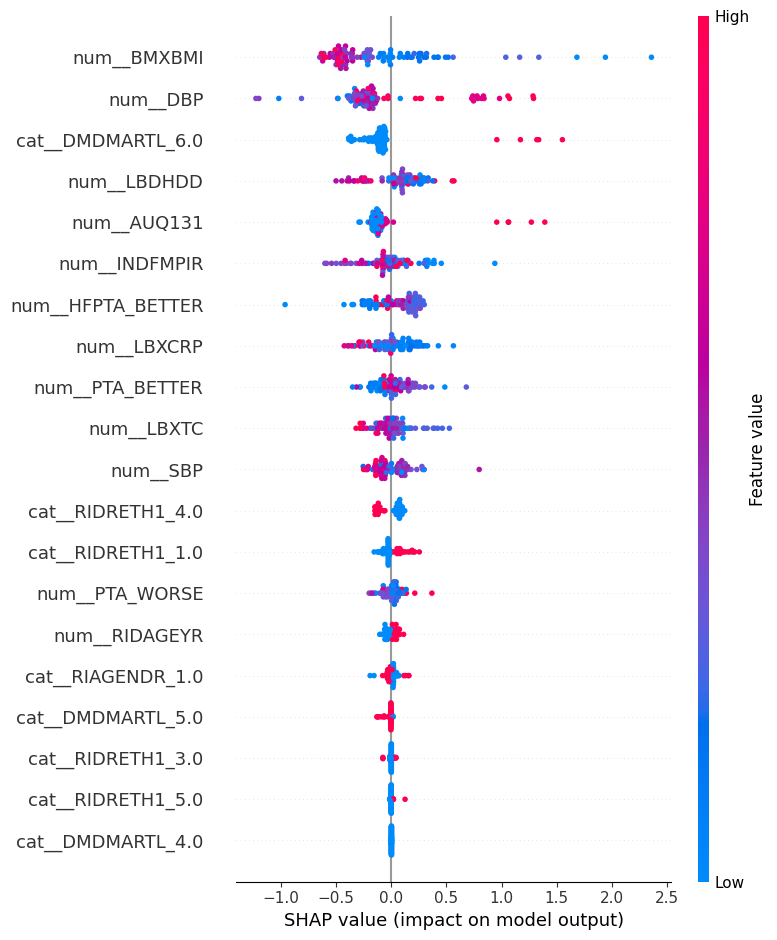

In [ ]:
def interpret(res, fitted, Xte, yte, label, n_repeats=30):
    cand = res[~res["model"].str.startswith("Mean-only")].sort_values("cv_rmse")
    best = cand.iloc[0]["model"]
    ref = res[res["model"].str.startswith("Mean-only")].iloc[0]["test_rmse"]
    print(f"\n[{label}] best model by CV RMSE: {best} "
          f"(test RMSE {cand.iloc[0]['test_rmse']:.3f} vs mean-only {ref:.3f})")
    pipe = fitted[best]
    imp = permutation_importance(pipe, Xte, yte, n_repeats=n_repeats, random_state=SEED,
                                 scoring="neg_root_mean_squared_error")
    out = pd.DataFrame({"feature": Xte.columns, "type": [PRED_TYPE.get(c, "?") for c in Xte.columns],
                        "rmse_increase": imp.importances_mean, "sd": imp.importances_std})
    out = out.sort_values("rmse_increase", ascending=False).reset_index(drop=True)
    print(out.round(4).to_string(index=False))
    return best, pipe

best_b, pipe_b = interpret(res_b, fit_b, Xte_b, yte_b, "(b) hearing + all")

# ---- SHAP (optional; tree models only) ----
try:
    import shap
    inner = pipe_b.named_steps["model"]
    if best_b in ("Random forest", "Gradient boosting", "XGBoost"):
        Xt = pipe_b.named_steps["pre"].transform(Xte_b)
        names = pipe_b.named_steps["pre"].get_feature_names_out()
        sv = shap.TreeExplainer(inner).shap_values(Xt)
        shap.summary_plot(sv, Xt, feature_names=names, show=True)
    else:
        print("SHAP skipped: best model is not tree-based.")
except ImportError:
    print("SHAP not installed (`pip install shap`) - skipping.")
except Exception as e:
    print(f"SHAP skipped: {e}")

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC

PHQ_CUTOFF, MIN_CASES = 10, 25
yb_all = (analytic["PHQ9"] >= PHQ_CUTOFF).astype(int).values
n_pos, n_neg = int(yb_all.sum()), int((1 - yb_all).sum())
print(f"PHQ-9 >= {PHQ_CUTOFF}: {n_pos} cases / {n_neg} non-cases ({n_pos / len(yb_all) * 100:.1f}%)")

def run_binary(label, feats):
    X = analytic[feats]
    Xtr, Xte, ytr, yte = train_test_split(X, yb_all, test_size=0.2, random_state=SEED, stratify=yb_all)
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    models = {
        "Logistic (baseline)": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.3),
        "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                class_weight="balanced_subsample",
                                                random_state=SEED, n_jobs=-1),
        "Gradient boosting": GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                                        learning_rate=0.03, subsample=0.8,
                                                        random_state=SEED),
        "SVM (RBF)": SVC(C=1.0, probability=True, class_weight="balanced", random_state=SEED),
    }
    rows = []
    for name, model in models.items():
        pipe = Pipeline([("pre", make_preprocessor(feats)), ("model", model)])
        cv_auc = cross_validate(pipe, Xtr, ytr, cv=cv, scoring="roc_auc")["test_score"]
        pipe.fit(Xtr, ytr)
        proba = pipe.predict_proba(Xte)[:, 1]
        tn, fp, fn, tp = confusion_matrix(yte, (proba >= 0.5).astype(int), labels=[0, 1]).ravel()
        rows.append({"model": name, "cv_auc": cv_auc.mean(), "cv_auc_sd": cv_auc.std(),
                     "test_auc": roc_auc_score(yte, proba),
                     "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1)})
    print(f"\n=== Binary: {label} ({len(feats)} predictors; test set has {int(yte.sum())} cases) ===")
    print(pd.DataFrame(rows).round(3).to_string(index=False))

if min(n_pos, n_neg) < MIN_CASES:
    print(f"Skipping binary models: fewer than {MIN_CASES} cases in one class.")
else:
    run_binary("(a) Hearing-only", HEARING_FEATS)
    run_binary("(b) Hearing + all predictors", ALL_PRED)

PHQ-9 >= 10: 25 cases / 436 non-cases (5.4%)

=== Binary: (a) Hearing-only (4 predictors; test set has 5 cases) ===
              model  cv_auc  cv_auc_sd  test_auc  sensitivity  specificity
Logistic (baseline)   0.582      0.181     0.536          0.6        0.477
      Random forest   0.590      0.096     0.659          0.2        0.909
  Gradient boosting   0.487      0.125     0.650          0.0        0.977
          SVM (RBF)   0.477      0.108     0.561          0.0        1.000

=== Binary: (b) Hearing + all predictors (15 predictors; test set has 5 cases) ===
              model  cv_auc  cv_auc_sd  test_auc  sensitivity  specificity
Logistic (baseline)   0.605      0.101     0.614          0.6        0.500
      Random forest   0.576      0.098     0.659          0.0        1.000
  Gradient boosting   0.531      0.119     0.705          0.0        0.989
          SVM (RBF)   0.506      0.102     0.530          0.0        1.000
